In [28]:
from google.colab import files
files.upload()
import zipfile
import os


with zipfile.ZipFile('/content/xai-series-master.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')


os.chdir('/content/xai-series-master')

print("Current directory:", os.getcwd())
print("\nRepository files:")
print(os.listdir())


Saving xai-series-master.zip to xai-series-master.zip
Current directory: /content/xai-series-master

Repository files:
['data', '00_data_exploration.py', '01_interpretable_models.py', '04_counterfactuals.py', 'outputs', '02_lime.py', '03_shap.py', '__pycache__', '05_lrp.py', 'utils.py', 'xai-series-master.zip']


In [5]:

%pip install -q imbalanced-learn shap


(5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
col:  id


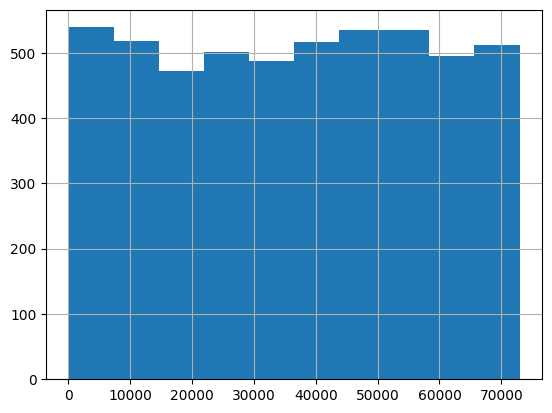

col:  gender


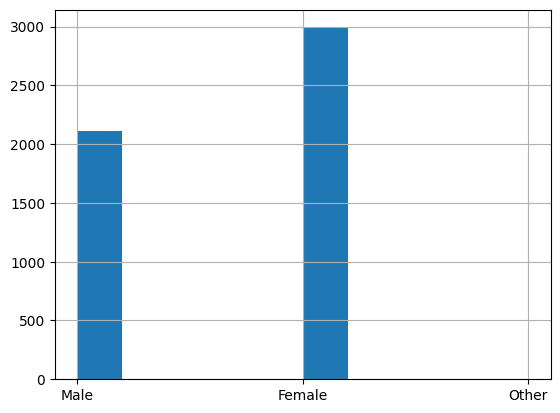

col:  age


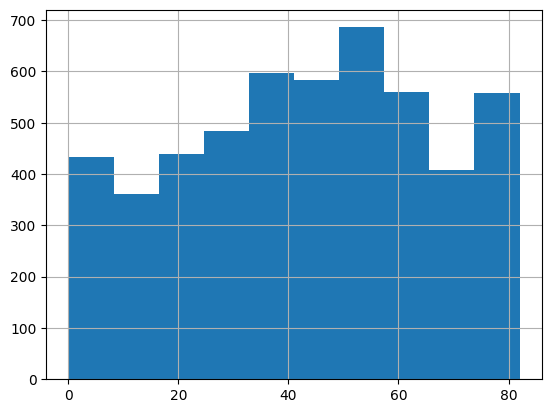

col:  hypertension


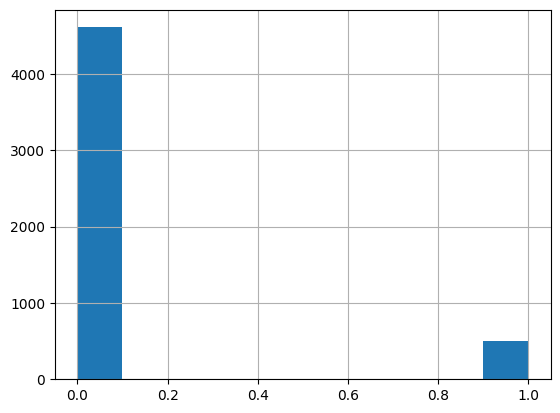

col:  heart_disease


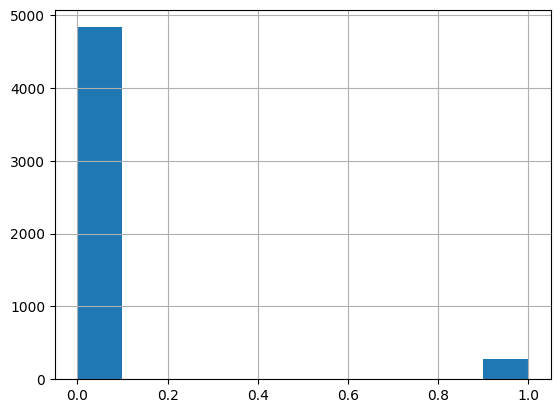

col:  ever_married


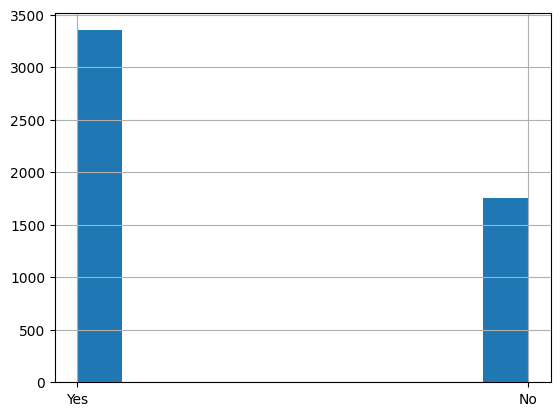

col:  work_type


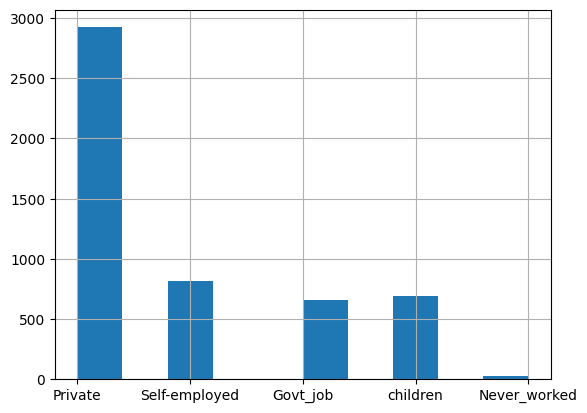

col:  Residence_type


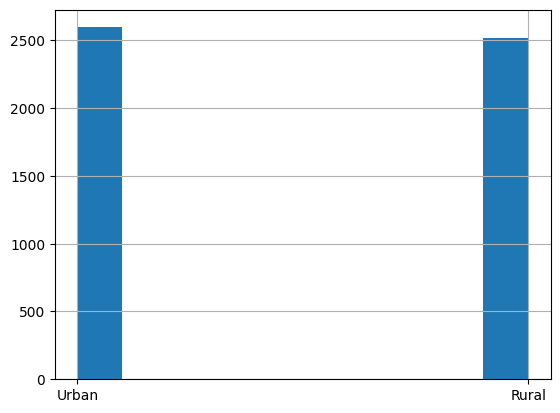

col:  avg_glucose_level


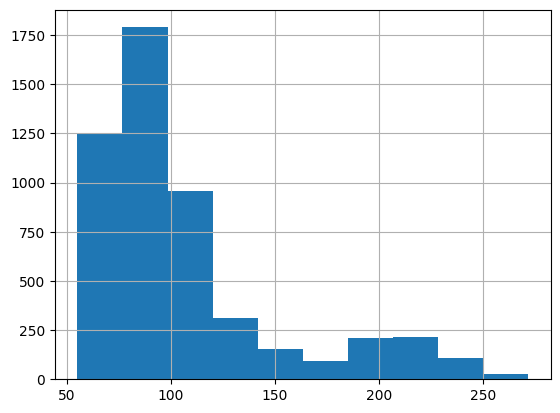

col:  bmi


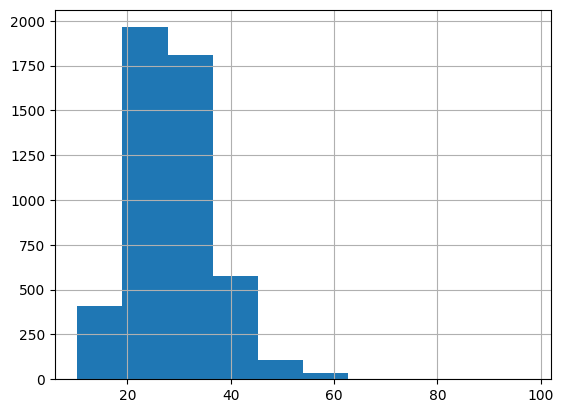

col:  smoking_status


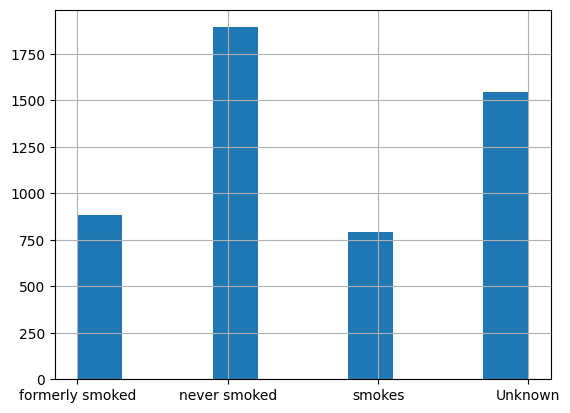

col:  stroke


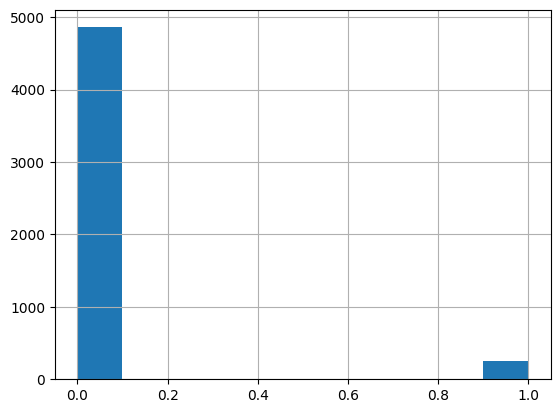

<Figure size 640x480 with 0 Axes>

In [6]:

%run 00_data_exploration.py


In [7]:

import pandas as pd

# Load the original dataset
df = pd.read_csv("data/healthcare-dataset-stroke-data.csv")

print("=== DATASET SHAPE ===")
print(df.shape)

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== STROKE CLASS DISTRIBUTION ===")
print(df["stroke"].value_counts())
print(df["stroke"].value_counts(normalize=True) * 100)

print("\n=== NUMERICAL STATISTICS ===")
print(df[["age", "avg_glucose_level", "bmi"]].describe())

print("\n=== DUPLICATE RECORDS ===")
print(df.duplicated().sum())

print("\n=== DUPLICATE PATIENT IDs ===")
print(df["id"].duplicated().sum())


=== DATASET SHAPE ===
(5110, 12)

=== MISSING VALUES ===
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

=== STROKE CLASS DISTRIBUTION ===
stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

=== NUMERICAL STATISTICS ===
               age  avg_glucose_level          bmi
count  5110.000000        5110.000000  4909.000000
mean     43.226614         106.147677    28.893237
std      22.612647          45.283560     7.854067
min       0.080000          55.120000    10.300000
25%      25.000000          77.245000    23.500000
50%      45.000000          91.885000    28.100000
75%      61.000000         114.090000    33.100000
max      82.000000         271.740

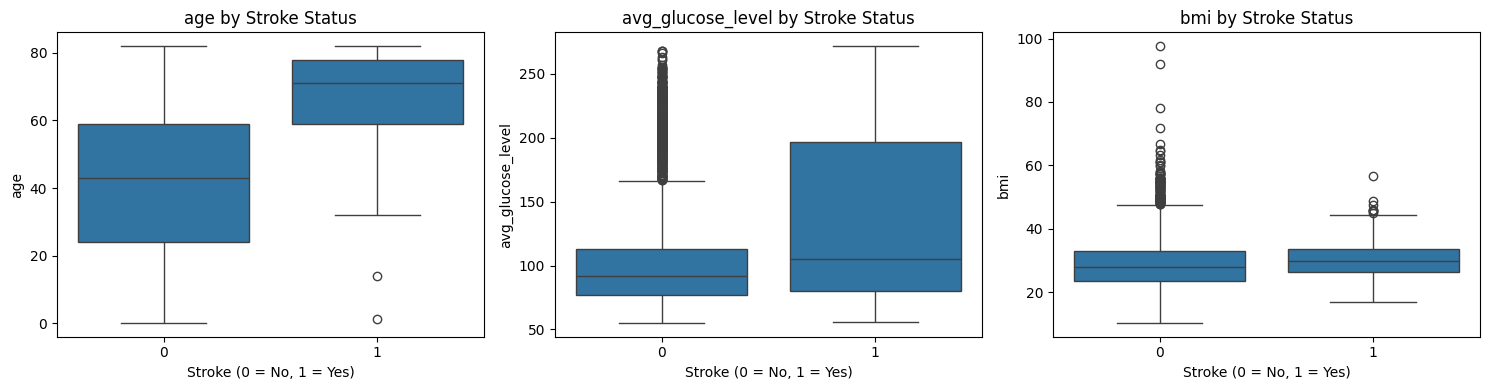


=== MEAN VALUES BY STROKE STATUS ===
          age  avg_glucose_level    bmi
stroke                                 
0       41.97             104.80  28.82
1       67.73             132.54  30.47


In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

features = ["age", "avg_glucose_level", "bmi"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="stroke",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Stroke Status")
    ax.set_xlabel("Stroke (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

print("\n=== MEAN VALUES BY STROKE STATUS ===")
print(df.groupby("stroke")[features].mean().round(2))


In [9]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import pandas as pd

# Separate predictors and target
X = df.drop(columns=["id", "stroke"])
y = df["stroke"]

# Split data: 80% training, 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=2021,
    stratify=y
)

# Handle missing BMI values using training data only
imputer = SimpleImputer(strategy="median")

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

X_train["bmi"] = imputer.fit_transform(
    X_train_raw[["bmi"]]
).ravel()

X_test["bmi"] = imputer.transform(
    X_test_raw[["bmi"]]
).ravel()

# Encode categorical variables
categorical_cols = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nMissing values after preprocessing:")
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())


Training data: (4088, 21)
Testing data: (1022, 21)

Training class distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing class distribution:
stroke
0    972
1     50
Name: count, dtype: int64

Missing values after preprocessing:
0
0


In [10]:

from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Oversample training data only
ros = RandomOverSampler(random_state=2021)
X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train, y_train
)

print("=== BALANCED TRAINING DATA ===")
print(y_train_balanced.value_counts())

# Train Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=2021,
    n_jobs=-1
)

rf.fit(X_train_balanced, y_train_balanced)


y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]


print("\n=== RANDOM FOREST PERFORMANCE ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Precision (Stroke):", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall (Stroke):", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score (Stroke):", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, y_prob), 4))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred))


=== BALANCED TRAINING DATA ===
stroke
0    3889
1    3889
Name: count, dtype: int64

=== RANDOM FOREST PERFORMANCE ===
Accuracy: 0.9403
Balanced Accuracy: 0.5133
Precision (Stroke): 0.1333
Recall (Stroke): 0.04
F1 Score (Stroke): 0.0615
ROC AUC: 0.827
Average Precision: 0.1454

=== CONFUSION MATRIX ===
[[959  13]
 [ 48   2]]


In [11]:

import shap
import numpy as np

# Create SHAP explainer for Random Forest
explainer = shap.TreeExplainer(rf)


shap_values = explainer.shap_values(X_test)


print("SHAP version:", shap.__version__)
print("Model classes:", rf.classes_)
print("SHAP values shape:", np.shape(shap_values))
print("Expected values:", explainer.expected_value)

# Select SHAP values for stroke = 1
if isinstance(shap_values, list):
    shap_values_stroke = shap_values[1]
else:
    shap_values_stroke = shap_values[:, :, 1]

print("\nStroke-class SHAP shape:", shap_values_stroke.shape)
print("Number of features:", X_test.shape[1])


SHAP version: 0.54.1
Model classes: [0 1]
SHAP values shape: (1022, 21, 2)
Expected values: [0.4995243 0.5004757]

Stroke-class SHAP shape: (1022, 21)
Number of features: 21


In [12]:

# Find a false-negative case
false_negative_indices = np.where(
    (y_test.to_numpy() == 1) & (y_pred == 0)
)[0]

# Select the first false-negative case
case_idx = int(false_negative_indices[0])


print("Case index:", case_idx)
print("Actual stroke:", y_test.iloc[case_idx])
print("Predicted stroke:", y_pred[case_idx])
print("Predicted probability:", round(y_prob[case_idx], 4))

# Check SHAP reconstruction
base_value = explainer.expected_value[1]
shap_sum = shap_values_stroke[case_idx].sum()

print("\nSHAP base value:", round(base_value, 4))
print("SHAP reconstructed output:", round(base_value + shap_sum, 4))


shap.initjs()

shap.force_plot(
    base_value,
    shap_values_stroke[case_idx],
    X_test.iloc[case_idx],
    matplotlib=False
)


Case index: 32
Actual stroke: 1
Predicted stroke: 0
Predicted probability: 0.21

SHAP base value: 0.5005
SHAP reconstructed output: 0.21


In [13]:

# Extract the selected patient's SHAP contributions
local_contributions = pd.DataFrame({
    "Feature": X_test.columns,
    "Patient Value": X_test.iloc[case_idx].values,
    "SHAP Value": shap_values_stroke[case_idx]
})


local_contributions["Absolute SHAP"] = (
    local_contributions["SHAP Value"].abs()
)

local_contributions = local_contributions.sort_values(
    "Absolute SHAP",
    ascending=False
)

print("=== TOP 10 FEATURE CONTRIBUTIONS ===")
print(local_contributions.head(10).to_string(index=False))

print("\n=== SHAP RECONSTRUCTION CHECK ===")
print("Base value:", round(float(base_value), 6))
print("Sum of contributions:", round(float(shap_sum), 6))
print("Reconstructed output:", round(float(base_value + shap_sum), 6))
print("Model probability:", round(float(y_prob[case_idx]), 6))
print("Absolute difference:",
      abs(float(base_value + shap_sum) - float(y_prob[case_idx])))


=== TOP 10 FEATURE CONTRIBUTIONS ===
                       Feature  Patient Value  SHAP Value  Absolute SHAP
             avg_glucose_level          91.02   -0.171598       0.171598
                           bmi          32.90   -0.130531       0.130531
                  hypertension           1.00    0.079326       0.079326
                           age          80.00    0.036238       0.036238
          Residence_type_Rural           1.00   -0.026787       0.026787
   smoking_status_never smoked           0.00   -0.016399       0.016399
          Residence_type_Urban           0.00   -0.016193       0.016193
                 gender_Female           1.00   -0.009284       0.009284
smoking_status_formerly smoked           1.00   -0.008808       0.008808
                 heart_disease           0.00   -0.008593       0.008593

=== SHAP RECONSTRUCTION CHECK ===
Base value: 0.500476
Sum of contributions: -0.290476
Reconstructed output: 0.21
Model probability: 0.21
Absolute difference: 

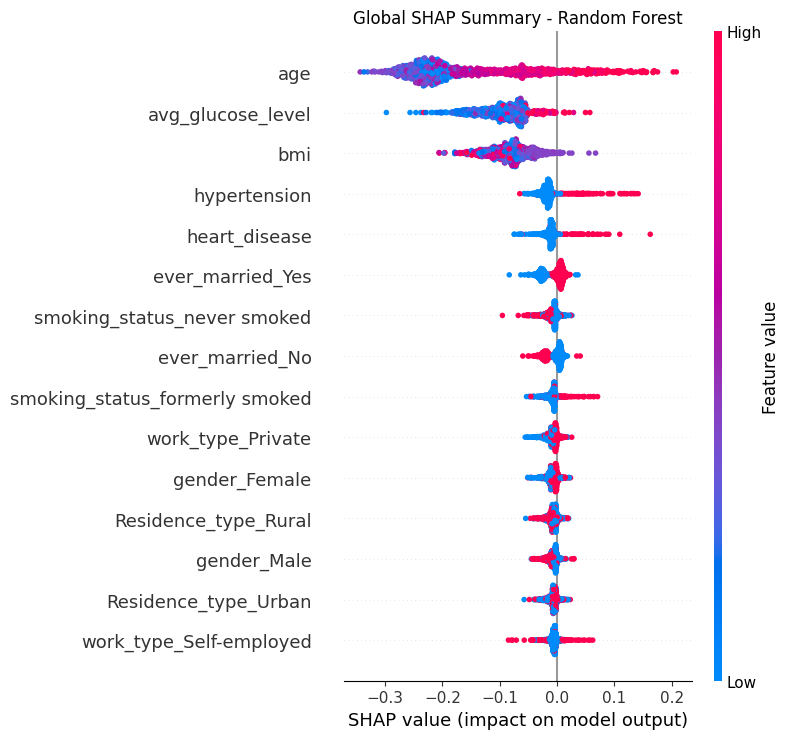


=== TOP 10 GLOBAL FEATURES ===
                       Feature  Mean Absolute SHAP
                           age            0.164689
             avg_glucose_level            0.092782
                           bmi            0.082159
                  hypertension            0.021415
                 heart_disease            0.013796
              ever_married_Yes            0.013758
   smoking_status_never smoked            0.010582
               ever_married_No            0.010510
smoking_status_formerly smoked            0.009775
             work_type_Private            0.008660


In [14]:

import matplotlib.pyplot as plt


shap.summary_plot(
    shap_values_stroke,
    X_test,
    max_display=15,
    show=False
)

plt.title("Global SHAP Summary - Random Forest")
plt.tight_layout()
plt.show()

# Calculate global feature importance
global_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": np.abs(shap_values_stroke).mean(axis=0)
})

global_importance = global_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

print("\n=== TOP 10 GLOBAL FEATURES ===")
print(global_importance.head(10).to_string(index=False))


In [15]:

import os
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)


shap.summary_plot(
    shap_values_stroke,
    X_test,
    max_display=15,
    show=False
)
plt.savefig(
    "outputs/global_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


shap.save_html(
    "outputs/local_force_plot.html",
    shap.force_plot(
        base_value,
        shap_values_stroke[case_idx],
        X_test.iloc[case_idx]
    )
)

print("Global summary plot saved.")
print("Local force plot saved.")
print("Output files:", os.listdir("outputs"))


Global summary plot saved.
Local force plot saved.
Output files: ['local_force_plot.html', 'global_shap_summary.png']


In [16]:


plt.figure(figsize=(16, 3))

shap.force_plot(
    base_value,
    shap_values_stroke[case_idx],
    X_test.iloc[case_idx],
    matplotlib=True,
    show=False,
    figsize=(16, 3)
)

plt.savefig(
    "outputs/local_force_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")

print("Local force plot PNG saved.")
print("Output files:", os.listdir("outputs"))


Local force plot PNG saved.
Output files: ['local_force_plot.html', 'local_force_plot.png', 'global_shap_summary.png']


In [17]:

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Standardize features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a different black-box model: SVM
svm = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=2021
)

svm.fit(X_train_scaled, y_train)


svm_pred = svm.predict(X_test_scaled)
svm_prob = svm.predict_proba(X_test_scaled)[:, 1]

print("=== SVM PERFORMANCE ===")
print("Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, svm_pred), 4))
print("Precision (Stroke):", round(precision_score(y_test, svm_pred, zero_division=0), 4))
print("Recall (Stroke):", round(recall_score(y_test, svm_pred, zero_division=0), 4))
print("F1 Score (Stroke):", round(f1_score(y_test, svm_pred, zero_division=0), 4))
print("ROC AUC:", round(roc_auc_score(y_test, svm_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, svm_prob), 4))

print("\n=== SVM CONFUSION MATRIX ===")
print(confusion_matrix(y_test, svm_pred))

print("\nTraining samples:", X_train_scaled.shape)
print("Testing samples:", X_test_scaled.shape)



=== SVM PERFORMANCE ===
Accuracy: 0.7534
Balanced Accuracy: 0.6996
Precision (Stroke): 0.1203
Recall (Stroke): 0.64
F1 Score (Stroke): 0.2025
ROC AUC: 0.8016
Average Precision: 0.1622

=== SVM CONFUSION MATRIX ===
[[738 234]
 [ 18  32]]

Training samples: (4088, 21)
Testing samples: (1022, 21)


In [18]:

import shap
import numpy as np


rng = np.random.default_rng(2021)

background_idx = rng.choice(
    len(X_train_scaled),
    size=30,
    replace=False
)

background = X_train_scaled[background_idx]

# Select 40 test samples, including our original patient
other_indices = np.setdiff1d(
    np.arange(len(X_test_scaled)),
    [case_idx]
)

sampled_indices = rng.choice(
    other_indices,
    size=39,
    replace=False
)

kernel_indices = np.concatenate(
    ([case_idx], sampled_indices)
)

X_kernel = X_test_scaled[kernel_indices]


kernel_explainer = shap.KernelExplainer(
    svm.predict_proba,
    background
)

print("Kernel SHAP explainer created.")
print("Background shape:", background.shape)
print("Explanation sample shape:", X_kernel.shape)
print("Selected patient index:", case_idx)
print("SVM patient probability:", round(svm_prob[case_idx], 4))


Kernel SHAP explainer created.
Background shape: (30, 21)
Explanation sample shape: (40, 21)
Selected patient index: 32
SVM patient probability: 0.178


In [19]:

import time

# Calculate Kernel SHAP values
start_time = time.time()

kernel_shap_values = kernel_explainer.shap_values(
    X_kernel,
    nsamples=100
)

kernel_runtime = time.time() - start_time

# Select contributions for stroke class (1)
if isinstance(kernel_shap_values, list):
    kernel_shap_stroke = kernel_shap_values[1]
else:
    kernel_shap_stroke = kernel_shap_values[:, :, 1]

print("\n=== KERNEL SHAP RESULTS ===")
print("SHAP values shape:", np.shape(kernel_shap_values))
print("Stroke-class shape:", kernel_shap_stroke.shape)
print("Expected values:", kernel_explainer.expected_value)
print("Runtime (seconds):", round(kernel_runtime, 2))

svm_base = float(kernel_explainer.expected_value[1])
svm_shap_sum = float(kernel_shap_stroke[0].sum())
svm_reconstructed = svm_base + svm_shap_sum

print("\n=== PATIENT 32 VERIFICATION ===")
print("Base value:", round(svm_base, 6))
print("Sum of contributions:", round(svm_shap_sum, 6))
print("Reconstructed output:", round(svm_reconstructed, 6))
print("SVM probability:", round(float(svm_prob[case_idx]), 6))
print("Absolute difference:",
      abs(svm_reconstructed - float(svm_prob[case_idx])))


  0%|          | 0/40 [00:00<?, ?it/s]


=== KERNEL SHAP RESULTS ===
SHAP values shape: (40, 21, 2)
Stroke-class shape: (40, 21)
Expected values: [0.94792968 0.05207032]
Runtime (seconds): 18.4

=== PATIENT 32 VERIFICATION ===
Base value: 0.05207
Sum of contributions: 0.125965
Reconstructed output: 0.178036
SVM probability: 0.178036
Absolute difference: 0.0


=== SVM LOCAL EXPLANATION: PATIENT 32 ===


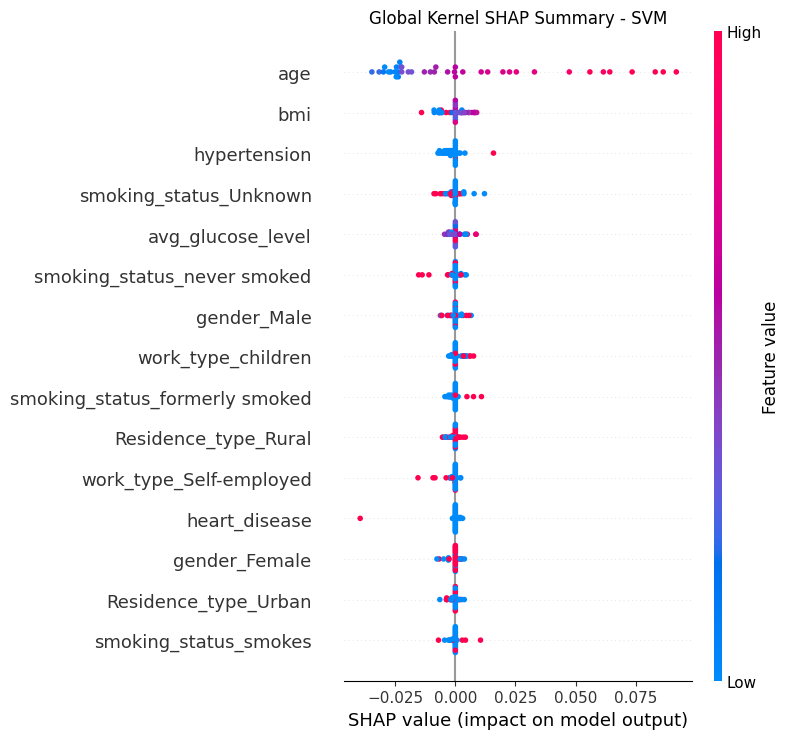


=== TOP 10 SVM GLOBAL FEATURES ===
                       Feature  Mean Absolute SHAP
                           age            0.029148
                           bmi            0.004157
                  hypertension            0.002660
        smoking_status_Unknown            0.002223
             avg_glucose_level            0.001971
   smoking_status_never smoked            0.001866
                   gender_Male            0.001538
            work_type_children            0.001480
smoking_status_formerly smoked            0.001474
          Residence_type_Rural            0.001473


In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Restore readable feature names for the scaled data
X_kernel_display = pd.DataFrame(
    X_test.iloc[kernel_indices].to_numpy(),
    columns=X_test.columns
)


shap.initjs()

print("=== SVM LOCAL EXPLANATION: PATIENT 32 ===")

display(
    shap.force_plot(
        svm_base,
        kernel_shap_stroke[0],
        X_kernel_display.iloc[0],
        matplotlib=False
    )
)


shap.summary_plot(
    kernel_shap_stroke,
    X_kernel_display,
    max_display=15,
    show=False
)

plt.title("Global Kernel SHAP Summary - SVM")
plt.tight_layout()
plt.show()


svm_global_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": np.abs(kernel_shap_stroke).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

print("\n=== TOP 10 SVM GLOBAL FEATURES ===")
print(svm_global_importance.head(10).to_string(index=False))


In [21]:

import os
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)


shap.summary_plot(
    kernel_shap_stroke,
    X_kernel_display,
    max_display=15,
    show=False
)

plt.savefig(
    "outputs/svm_global_shap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")


svm_force = shap.force_plot(
    svm_base,
    kernel_shap_stroke[0],
    X_kernel_display.iloc[0]
)

shap.save_html(
    "outputs/svm_local_force.html",
    svm_force
)


shap.force_plot(
    svm_base,
    kernel_shap_stroke[0],
    X_kernel_display.iloc[0],
    matplotlib=True,
    show=False,
    figsize=(16, 3)
)

plt.savefig(
    "outputs/svm_local_force.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close("all")

print("=== SAVED OUTPUTS ===")
for filename in sorted(os.listdir("outputs")):
    print(filename)


=== SAVED OUTPUTS ===
global_shap_summary.png
local_force_plot.html
local_force_plot.png
svm_global_shap.png
svm_local_force.html
svm_local_force.png


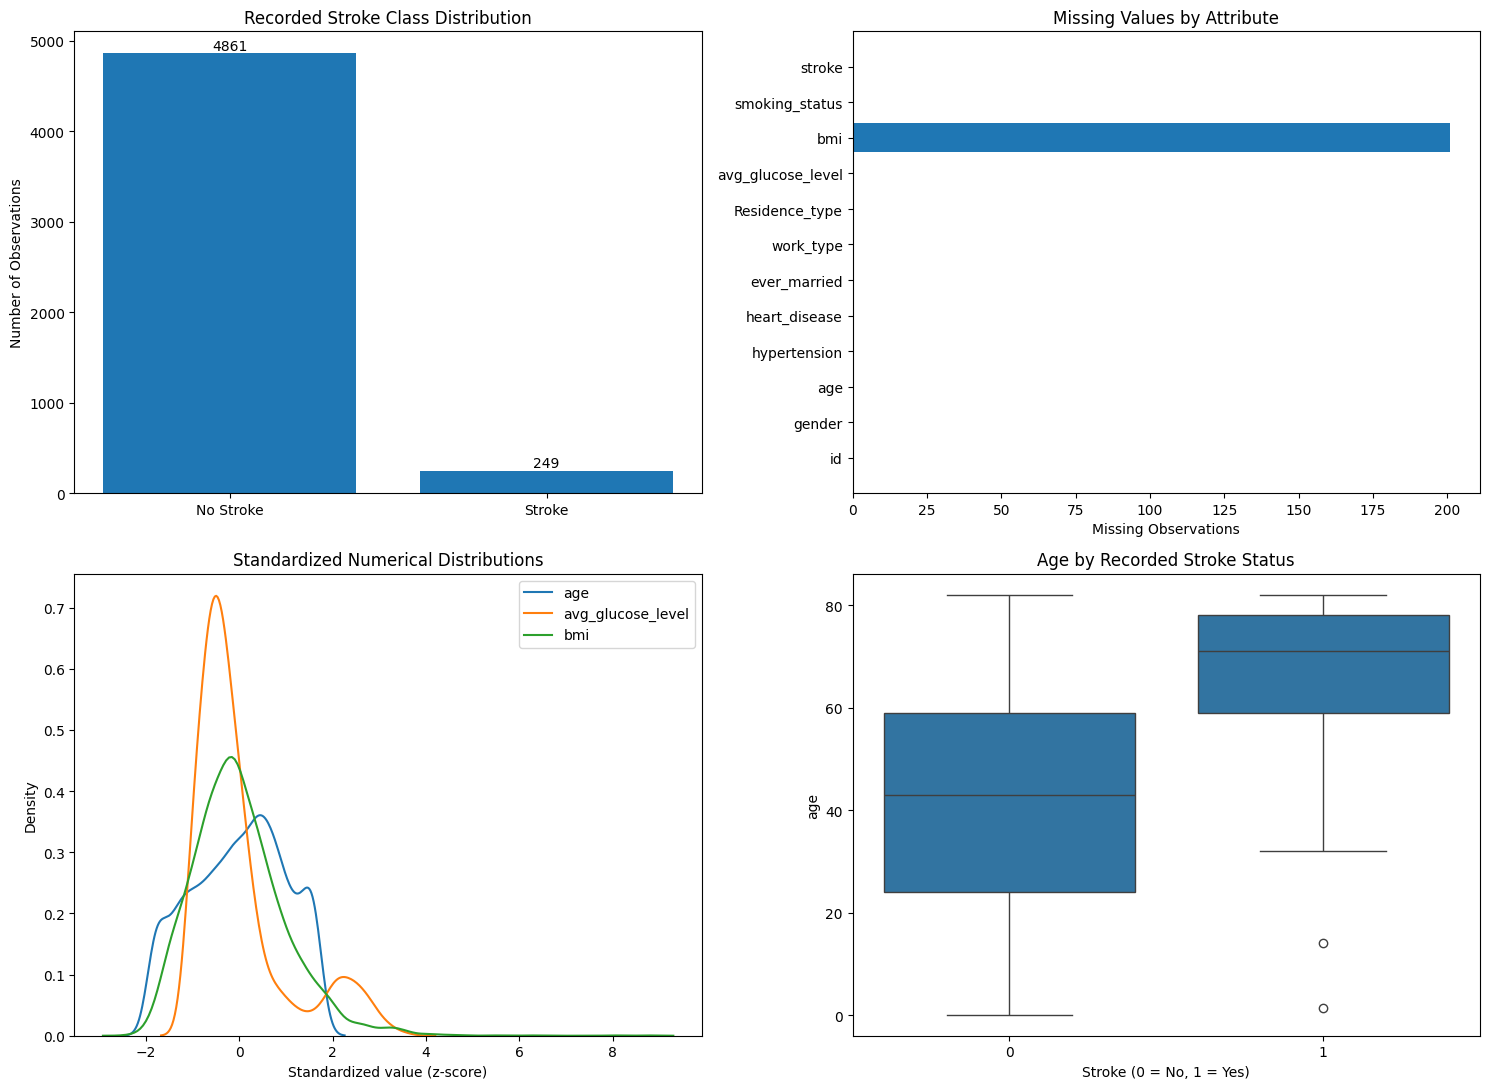

EDA figure saved: outputs/eda_panel.png


In [25]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the original dataset for EDA
df_eda = pd.read_csv(
    "/content/xai-series-master/data/healthcare-dataset-stroke-data.csv"
)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Stroke class distribution
counts = df_eda["stroke"].value_counts().sort_index()
axes[0, 0].bar(["No Stroke", "Stroke"], counts.values)
axes[0, 0].set_title("Recorded Stroke Class Distribution")
axes[0, 0].set_ylabel("Number of Observations")

for i, count in enumerate(counts.values):
    axes[0, 0].text(i, count + 40, str(count), ha="center")

# 2. Missing values
missing = df_eda.isnull().sum()
axes[0, 1].barh(missing.index, missing.values)
axes[0, 1].set_title("Missing Values by Attribute")
axes[0, 1].set_xlabel("Missing Observations")

# 3. Numerical distributions
numerical = ["age", "avg_glucose_level", "bmi"]

for feature in numerical:
    values = df_eda[feature].dropna()
    standardized = (values - values.mean()) / values.std()
    sns.kdeplot(
        x=standardized,
        ax=axes[1, 0],
        label=feature
    )

axes[1, 0].set_title("Standardized Numerical Distributions")
axes[1, 0].set_xlabel("Standardized value (z-score)")
axes[1, 0].legend()

# 4. Age comparison by stroke status
sns.boxplot(
    data=df_eda,
    x="stroke",
    y="age",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Age by Recorded Stroke Status")
axes[1, 1].set_xlabel("Stroke (0 = No, 1 = Yes)")

plt.tight_layout()

os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/eda_panel.png", dpi=300, bbox_inches="tight")
plt.show()

print("EDA figure saved: outputs/eda_panel.png")


In [27]:

import sys
import platform
import hashlib
import importlib.metadata as metadata

print("=== ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())

for package in [
    "numpy", "pandas", "scikit-learn",
    "imbalanced-learn", "shap",
    "matplotlib", "seaborn"
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")

print("\n=== DATASET FINGERPRINT ===")
dataset_path = (
    "/content/xai-series-master/data/"
    "healthcare-dataset-stroke-data.csv"
)
with open(dataset_path, "rb") as f:
    print("SHA-256:", hashlib.sha256(f.read()).hexdigest())

print("\n=== MODEL PARAMETERS ===")
print("Random Forest:", rf.get_params())
print("SVM:", svm.get_params())


=== ENVIRONMENT ===
Python: 3.13.18
Operating system: Linux-6.6.159+-x86_64-with-glibc2.39
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
shap: 0.54.1
matplotlib: 3.10.0
seaborn: 0.13.2

=== DATASET FINGERPRINT ===
SHA-256: 644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420

=== MODEL PARAMETERS ===
Random Forest: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 2021, 'verbose': 0, 'warm_start': False}
SVM: {'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': 'balanced', 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': True, 'random_state'